# Highlights Analysis


## Import Libraries and Data

In [1]:
from matplotlib.patches import Patch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

highlights_index = pd.read_csv("highlights_index.csv")

## Import Median Error Margins

In [2]:
ga_dem_median_error_margin = float(highlights_index.iloc[3, 1])
ga_rep_median_error_margin = float(highlights_index.iloc[4, 1])
ga_3rd_median_error_margin = float(highlights_index.iloc[5, 1])

me_dem_median_error_margin = float(highlights_index.iloc[9, 1])
me_rep_median_error_margin = float(highlights_index.iloc[10, 1])
me_3rd_median_error_margin = float(highlights_index.iloc[11, 1])

mi_dem_median_error_margin = float(highlights_index.iloc[15, 1])
mi_rep_median_error_margin = float(highlights_index.iloc[16, 1])
mi_3rd_median_error_margin = float(highlights_index.iloc[17, 1])

print((ga_dem_median_error_margin, ga_rep_median_error_margin, ga_3rd_median_error_margin))
print((me_dem_median_error_margin, me_rep_median_error_margin, me_3rd_median_error_margin))
print((mi_dem_median_error_margin, mi_rep_median_error_margin, mi_3rd_median_error_margin))

(0.1242, 0.0037, -3.0325)
(-0.1661, 0.0659, -0.2101)
(0.3, 3.8449, -4.87)


## Import final forecast analysis data

In [3]:
ga_dem_final_percentage = float(highlights_index.iloc[0, 1])
ga_rep_final_percentage = float(highlights_index.iloc[1, 1])
ga_3rd_final_percentage = float(highlights_index.iloc[2, 1])

me_dem_final_percentage = float(highlights_index.iloc[6, 1])
me_rep_final_percentage = float(highlights_index.iloc[7, 1])
me_3rd_final_percentage = float(highlights_index.iloc[8, 1])

mi_dem_final_percentage = float(highlights_index.iloc[12, 1])
mi_rep_final_percentage = float(highlights_index.iloc[13, 1])
mi_3rd_final_percentage = float(highlights_index.iloc[14, 1])

## Create Bar Chart for final forecast

{'GA': {'DEM': 34.4, 'REP': 50.0, 'THIRD': 15.6}, 'ME': {'DEM': 36.9, 'REP': 37.0, 'THIRD': 26.1}, 'MI': {'DEM': 52.2, 'REP': 36.0, 'THIRD': 11.9}}


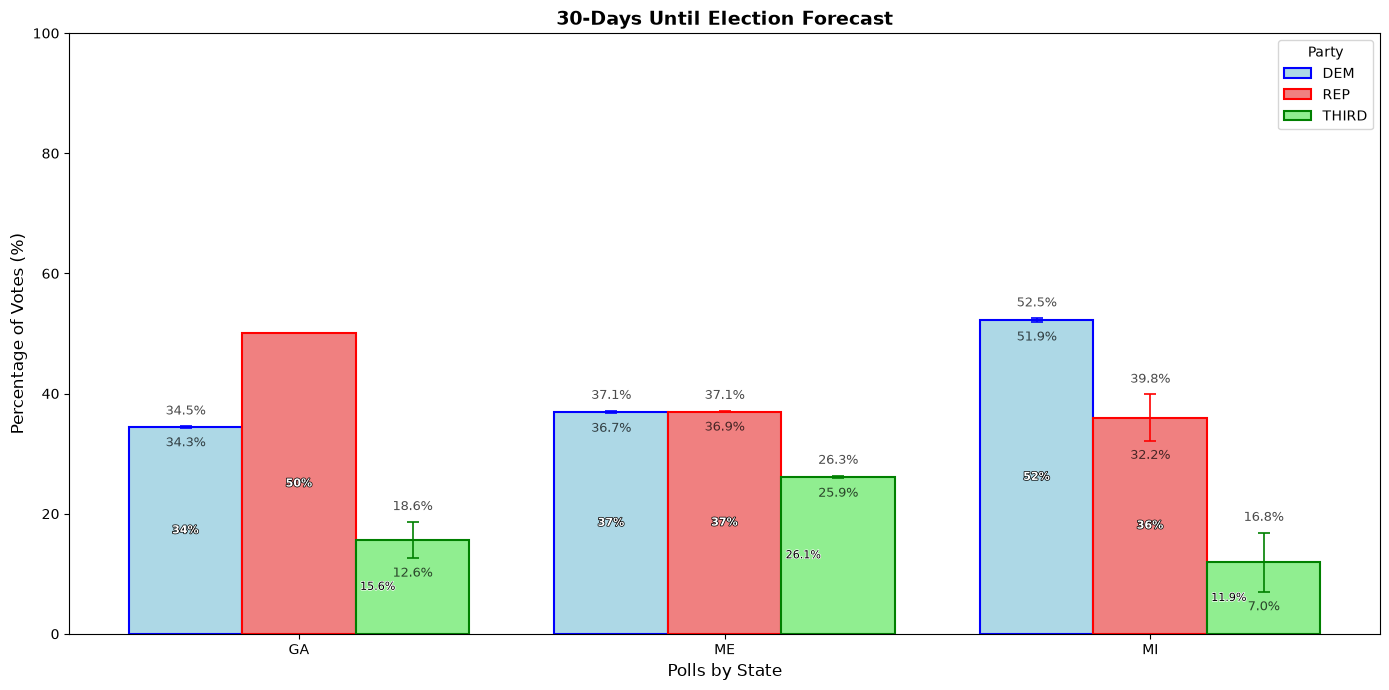

In [4]:
# =====================================================================
# STEP 1: Organize the raw data into a clean, easy-to-read structure
# =====================================================================

# The states we're comparing, and the parties in each state
states = ["GA", "ME", "MI"]
parties = ["DEM", "REP", "THIRD"]

# For each state, store its polling percentages for all three parties.
# Using a nested dict makes it much easier to look values up later.
polling_percentages = {
    "GA": {
        "DEM":   ga_dem_final_percentage,
        "REP":   ga_rep_final_percentage,
        "THIRD": ga_3rd_final_percentage,
    },
    "ME": {
        "DEM":   me_dem_final_percentage,
        "REP":   me_rep_final_percentage,
        "THIRD": me_3rd_final_percentage,
    },
    "MI": {
        "DEM":   mi_dem_final_percentage,
        "REP":   mi_rep_final_percentage,
        "THIRD": mi_3rd_final_percentage,
    },
}

print(polling_percentages)

# Same idea for the error margins. We take the absolute value so the
# error bars always point "outward" symmetrically.
error_margins = {
    "GA": {
        "DEM":   abs(ga_dem_median_error_margin),
        "REP":   abs(ga_rep_median_error_margin),
        "THIRD": abs(ga_3rd_median_error_margin),
    },
    "ME": {
        "DEM":   abs(me_dem_median_error_margin),
        "REP":   abs(me_rep_median_error_margin),
        "THIRD": abs(me_3rd_median_error_margin),
    },
    "MI": {
        "DEM":   abs(mi_dem_median_error_margin),
        "REP":   abs(mi_rep_median_error_margin),
        "THIRD": abs(mi_3rd_median_error_margin),
    },
}

# Colors for each party (face = fill, edge = border/error bar color)
party_colors = {
    "DEM":   {"face": "lightblue",  "edge": "blue"},
    "REP":   {"face": "lightcoral", "edge": "red"},
    "THIRD": {"face": "lightgreen", "edge": "green"},
}


# =====================================================================
# STEP 2: Figure out where each bar goes on the x-axis
# =====================================================================

# Each state gets a "cluster" of 3 bars, centered on its x position.
# The bars are offset from the cluster center so they sit side-by-side.
number_of_states = len(states)
number_of_parties = len(parties)

cluster_width = 0.8                        # total width of one state's cluster
bar_width = cluster_width / number_of_parties  # width of a single bar

# State x-positions: [0, 1, 2] for GA, ME, MI
state_x_positions = np.arange(number_of_states)

def bar_offset(party_index):
    """Return the horizontal offset for the i-th bar in a cluster."""
    return (party_index - (number_of_parties - 1) / 2) * bar_width


# =====================================================================
# STEP 3: Draw the chart
# =====================================================================

fig, ax = plt.subplots(figsize=(14, 7))

for state_index, state in enumerate(states):
    for party_index, party in enumerate(parties):
        value = polling_percentages[state][party]
        error = error_margins[state][party]
        colors = party_colors[party]

        # Where this specific bar goes on the x-axis
        x_position = state_x_positions[state_index] + bar_offset(party_index)

        # Draw the bar itself (with its error bar)
        ax.bar(
            x_position,
            value,
            width=bar_width,
            color=colors["face"],
            edgecolor=colors["edge"],
            linewidth=1.5,
            yerr=error,
            capsize=4,
            error_kw={
                "ecolor": colors["edge"],
                "elinewidth": 1.2,
                "capthick": 1.2,
            },
            # Only add the legend entry once (for the first state)
            label=party if state_index == 0 else None,
        )

        # Add the percentage label inside the bar
        label_text = f"{value:.1f}%" if (party == "THIRD" or value < 15) else f"{value:.0f}%"
        if party == "THIRD" or value < 15:
            # Small bars: put the label on the left edge with a white outline
            ax.text(
                x_position - bar_width / 2 + 0.01,
                value / 2,
                label_text,
                ha="left",
                va="center",
                fontsize=8,
                color="black",
                path_effects=[pe.withStroke(linewidth=1, foreground="white")],
            )
        else:
            # Tall bars: put the label in the middle with a black outline
            ax.text(
                x_position,
                value / 2,
                label_text,
                ha="center",
                va="center",
                fontsize=8,
                color="white",
                fontweight="bold",
                path_effects=[pe.withStroke(linewidth=1, foreground="black")],
            )

        # Add the upper and lower bound labels (from the error margin)
        upper_bound = round(value + error, 1)
        lower_bound = round(value - error, 1)
        if upper_bound != lower_bound:
            ax.text(
                x_position, upper_bound + 1.5,
                f"{upper_bound:.1f}%",
                ha="center", va="bottom",
                fontsize=9, color="black", alpha=0.7,
            )
            ax.text(
                x_position, lower_bound - 1.5,
                f"{lower_bound:.1f}%",
                ha="center", va="top",
                fontsize=9, color="black", alpha=0.7,
            )


# =====================================================================
# STEP 4: Create Chart Labels and Legend
# =====================================================================

ax.set_xticks(state_x_positions)
ax.set_xticklabels(states, fontsize=10)
ax.set_xlabel("Polls by State", fontsize=12)
ax.set_ylabel("Percentage of Votes (%)", fontsize=12)
ax.set_title("30-Days Until Election Forecast", fontsize=14, fontweight="bold")
ax.set_ylim(0, 100)
ax.legend(title="Party", loc="upper right")

plt.tight_layout()
plt.savefig("_static/images/final_election_forecast.png", dpi=300, bbox_inches="tight")
plt.show()